In [1]:
import warnings
warnings.simplefilter("ignore")

import mlflow
import os
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt 
import pandas as pd
import numpy as np
from simulation_study_analysis_helpers import *

import torch

# move to project root directory to find the mlruns folder with mlflow experiments
notebook_path = Path().resolve()
project_root = notebook_path.parent  # adjust as needed
os.chdir(project_root)

from simulation_studies.generate_synthetic_vine_data import generate_synthetic_vine_data


### First we need to compute all hessians for each model


In [3]:
mlflow.set_tracking_uri("file:mlruns_v1")

In [7]:
experiment_name = "rine_10D_500obs_bootstrap_hydra_fixed_copula_smaller_penlasso_adpative"
#experiment_name = "rine_5D_1000obs_bootstrap_hydra_fixed_copula_smaller"
experiment = mlflow.get_experiment_by_name(experiment_name) 
df_runs = mlflow.search_runs([experiment.experiment_id])

# subset all runs seed smaller 32
df_runs = df_runs[df_runs["tags.seed_value"].astype(int) < 32]#100]#32]

seed_value_copula = 0

df_structure = generate_synthetic_vine_data(seed_value=seed_value_copula,seed_value_copula=int(df_runs["tags.seed_value_copula"].iloc[0]), 
                                            dimensionality=int(df_runs["tags.dimensionality"].iloc[0]),
                                                Independence_tree=int(df_runs["tags.Independence_tree"].iloc[0]),
                                                vine_type="R-Vine",
                                            )["df_true_structure"]

bootstrap_bool = df_runs["tags.mlflow.runName"].str.contains("bootstrap")

bootstraped_runs = df_runs[bootstrap_bool]
original_runs = df_runs[bootstrap_bool==False]

In [ ]:
rel_hess_meaned_diff = []
for seed_value in range(0,15):#32):#100):#30):
    artifact_uri_bootstrapped = bootstraped_runs["artifact_uri"][bootstraped_runs["tags.seed_value"].astype(int)==seed_value].item()
    
    artifact_uri_original = original_runs["artifact_uri"][original_runs["tags.seed_value"].astype(int)==seed_value].item()
    
    synthetic_data_dict = generate_synthetic_vine_data(
        seed_value=seed_value,
        seed_value_copula=int(df_runs["tags.seed_value_copula"].iloc[0]), 
        dimensionality=int(df_runs["tags.dimensionality"].iloc[0]),
        Independence_tree=int(df_runs["tags.Independence_tree"].iloc[0]),
        vine_type="R-Vine",
        N_train=400,#800,#400,
        N_validate=100,#200,#100,
        N_test=10000
    )
    
    gtm_boot = mlflow.pytorch.load_model(artifact_uri_bootstrapped+"/model",map_location=torch.device('cpu'))
    gtm_boot.device="cpu"
    gtm_boot=gtm_boot.to("cpu")
    
    gtm_original = mlflow.pytorch.load_model(artifact_uri_original+"/model",map_location=torch.device('cpu'))
    gtm_original.device="cpu"
    gtm_original=gtm_original.to("cpu")
    
    
    rel_hess_boot = gtm_boot.compute_local_relative_hessian_metric(synthetic_data_dict["train_data"])
    rel_hess_original = gtm_original.compute_local_relative_hessian_metric(synthetic_data_dict["train_data"])
    
    rel_hess_meaned_diff.append(rel_hess_original.mean(0) - rel_hess_boot.mean(0))
    
rel_hess_meaned_diff_stacked = torch.stack(rel_hess_meaned_diff).detach()

2026/06/09 12:13:34 WARNING mlflow.pytorch: Stored model version '2.2.2+cu121' does not match installed PyTorch version '2.5.1'
2026/06/09 12:13:34 WARNING mlflow.pytorch: Stored model version '2.2.2+cu121' does not match installed PyTorch version '2.5.1'
2026/06/09 12:13:34 WARNING mlflow.pytorch: Stored model version '2.2.2+cu121' does not match installed PyTorch version '2.5.1'
2026/06/09 12:13:35 WARNING mlflow.pytorch: Stored model version '2.2.2+cu121' does not match installed PyTorch version '2.5.1'
2026/06/09 12:13:35 WARNING mlflow.pytorch: Stored model version '2.2.2+cu121' does not match installed PyTorch version '2.5.1'
2026/06/09 12:13:35 WARNING mlflow.pytorch: Stored model version '2.2.2+cu121' does not match installed PyTorch version '2.5.1'
2026/06/09 12:13:35 WARNING mlflow.pytorch: Stored model version '2.2.2+cu121' does not match installed PyTorch version '2.5.1'
2026/06/09 12:13:35 WARNING mlflow.pytorch: Stored model version '2.2.2+cu121' does not match installed 

In [9]:
# we recreate what we used following function for:
# plot_metric_bootstrap_intervals_for_each_seed(df_runs[:6],table_original_dict,table_diffs_list,df_structure,metric="kld",ylim=(-0.05,0.4))



for seed_value in range(0,32):#100):

    artifact_uri = original_runs["artifact_uri"][original_runs["tags.seed_value"].astype(int)==seed_value].item()

    gtm = mlflow.pytorch.load_model(artifact_uri+"/model",map_location=torch.device('cpu'))
    gtm.device="cpu"
    gtm=gtm.to("cpu")

    synthetic_data_dict = generate_synthetic_vine_data(
            seed_value=seed_value,
            seed_value_copula=int(df_runs["tags.seed_value_copula"].iloc[0]), 
            dimensionality=int(df_runs["tags.dimensionality"].iloc[0]),#10,
            Independence_tree=int(df_runs["tags.Independence_tree"].iloc[0]),
            vine_type="R-Vine",
            N_train=400,#800,#400,
            N_validate=100,#200,#100,
            N_test=10000
        )

    rel_hess = gtm.compute_local_relative_hessian_metric(synthetic_data_dict["train_data"])

    rel_hess_meaned_baseline = rel_hess.mean(0).detach()







    import numpy as np
    import matplotlib.pyplot as plt
    import seaborn as sns
    import pandas as pd

    D = int(df_runs["tags.dimensionality"].iloc[0]) #5#10

    # Collect all lower triangular (excluding diagonal) elements
    data_list = []
    labels = []
    indices = []

    for i in range(D):
        for j in range(i):  # j < i gives lower triangular, excluding diagonal
            values = rel_hess_meaned_diff_stacked[:, i, j] + rel_hess_meaned_baseline[i, j]
            data_list.append(values)
            labels.append(f"({i},{j})")
            indices.append((i, j))

    # Stack into DataFrame for seaborn
    df = pd.DataFrame(
        np.array(data_list).T,
        columns=labels
    )

    # Sort df_structure and build a lookup for dependence
    df_structure_sorted = df_structure.sort_values(["var_col", "var_row"])

    # Build color list based on dependence column
    colors = []
    for i, j in indices:
        # Look up the dependence value for this (i, j) pair
        match = df_structure_sorted[
            (df_structure_sorted["var_row"] == i) & 
            (df_structure_sorted["var_col"] == j)
        ]
        if match.empty:
            colors.append("gray")  # fallback if not found
        elif match["dependence"].values[0] == 0:
            colors.append("red")
        else:
            colors.append("blue")

    # Plot
    fig, ax = plt.subplots(figsize=(20, 5))

    sns.boxplot(
        data=df,
        whis=[2.5, 97.5],
        showfliers=False,
        palette=colors,
        ax=ax
    )

    ax.set_xticklabels(labels, rotation=90)
    ax.set_xlabel("(i, j) index")
    ax.set_ylabel("Value")
    ax.set_title("Lower Triangular Elements (excluding diagonal)")
    ax.axhline(0, color='black', linestyle='--', linewidth=0.8)

    # Add legend
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='blue', label='Dependent'),
        Patch(facecolor='red', label='Independent'),
    ]
    ax.legend(handles=legend_elements, loc='upper right')

    plt.tight_layout()
    plt.show()

2026/06/09 12:12:39 WARNING mlflow.pytorch: Stored model version '2.2.2+cu121' does not match installed PyTorch version '2.5.1'


NameError: name 'rel_hess_meaned_diff_stacked' is not defined

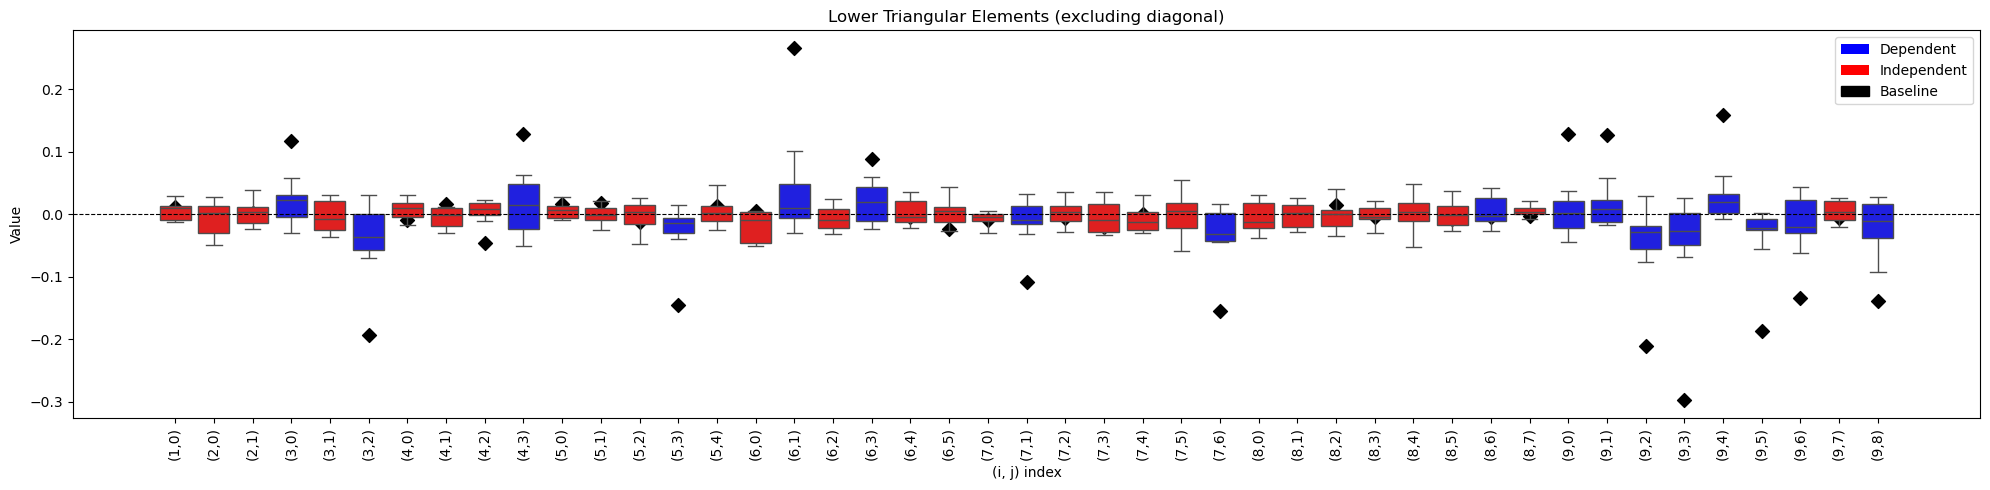

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from matplotlib.patches import Patch

D = int(df_runs["tags.dimensionality"].iloc[0])

data_list = []
labels = []
indices = []
baseline_points = []  # for baseline markers

for box_idx, (i, j) in enumerate(( (i, j) for i in range(D) for j in range(i) )):
    values = rel_hess_meaned_diff_stacked[:, i, j]
    data_list.append(values)
    labels.append(f"({i},{j})")
    indices.append((i, j))
    baseline_points.append(rel_hess_meaned_baseline[i, j])

df = pd.DataFrame(np.array(data_list).T, columns=labels)

# Dependence coloring, as before:
structure_lookup = {
    (row["var_row"], row["var_col"]): row["dependence"]
    for _, row in df_structure.iterrows()
}
colors = []
for (i, j) in indices:
    dep = structure_lookup.get((i, j), None)
    if dep is None:
        colors.append("gray")
    elif dep == 0:
        colors.append("red")
    else:
        colors.append("blue")

fig, ax = plt.subplots(figsize=(20, 5))

# Plot the boxplots
sns.boxplot(
    data=df,
    whis=[2.5, 97.5],
    showfliers=False,
    palette=colors,
    ax=ax
)

# Overlay a baseline marker for each group
x_positions = np.arange(len(labels))
ax.scatter(x_positions, baseline_points, color='black', marker='D', s=50, label='Baseline')

ax.set_xticklabels(labels, rotation=90)
ax.set_xlabel("(i, j) index")
ax.set_ylabel("Value")
ax.axhline(0, color='black', linestyle='--', linewidth=0.8)
ax.set_title("Lower Triangular Elements (excluding diagonal)")

legend_elements = [
    Patch(facecolor='blue', label='Dependent'),
    Patch(facecolor='red', label='Independent'),
    Patch(facecolor='black', label='Baseline', edgecolor='black')  # Baseline marker
]
ax.legend(handles=legend_elements, loc='upper right')

plt.tight_layout()
plt.show()